# Lab Assignment 9: Vision-based Cognitive Systems

## Part 1: Cognitive Assistant for Reading Medicine Bottle Labels

In [1]:
!pip install easyocr library-template -q

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


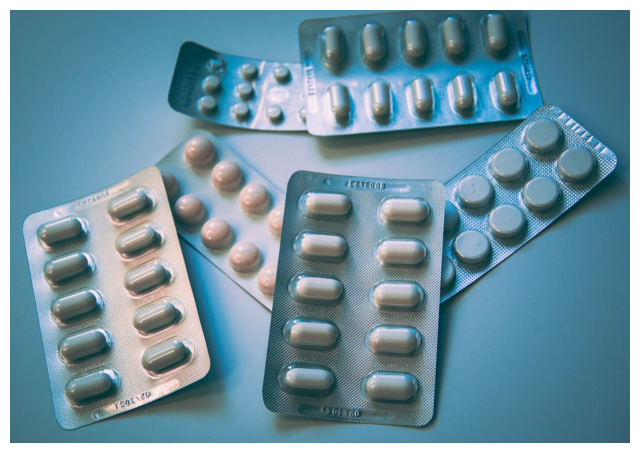

In [2]:
import cv2
import easyocr
import matplotlib.pyplot as plt
import urllib.request

reader = easyocr.Reader(['en'])

url = 'https://images.unsplash.com/photo-1584308666744-24d5c474f2ae?q=80&w=1000'
urllib.request.urlretrieve(url, 'medicine_bottle.jpg')

image = cv2.imread('medicine_bottle.jpg')
results = reader.readtext('medicine_bottle.jpg')

for (bbox, text, prob) in results:
    if prob > 0.4:
        print(f"Detected Text: {text} (Confidence: {prob:.2f})")
        pts = [tuple(map(int, pt)) for pt in bbox]
        cv2.polylines(image, [cv2.UMat(pts).get()], True, (0, 255, 0), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Part 2: Emotion-aware Cognitive Assistant using Facial Expression Detection

In [3]:
!pip install deepface -q

In [ ]:
from deepface import DeepFace
import cv2
import matplotlib.pyplot as plt
import urllib.request

face_url = 'https://images.unsplash.com/photo-1544005313-94ddf0286df2?q=80&w=1000'
urllib.request.urlretrieve(face_url, 'face_emotion.jpg')

try:
    analysis = DeepFace.analyze(img_path='face_emotion.jpg', actions=['emotion'])
    if isinstance(analysis, list):
        analysis = analysis[0]

    print("Dominant Emotion:", analysis['dominant_emotion'])
    print("Emotion Details:", analysis['emotion'])

    img = cv2.imread('face_emotion.jpg')
    x, y, w, h = analysis['region']['x'], analysis['region']['y'], analysis['region']['w'], analysis['region']['h']
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 0, 255), 2)
    cv2.putText(img, analysis['dominant_emotion'], (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)

    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
except Exception as e:
    print("Error analyzing face:", e)